In [1]:
# Run this cell ONCE in the VS Code terminal if needed:
# pip install rasterio geopandas scikit-learn matplotlib pandas numpy shapely pyproj



In [1]:
import re
import zipfile
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.warp import reproject, Resampling
from rasterio.features import rasterize

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    cohen_kappa_score,
)

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")



All libraries imported successfully.


In [2]:
# Put these two ZIP files in the SAME folder as this Python file:
#
# Browser_images.zip
# sawah.zip

IMAGES_ZIP = Path("Browser_images.zip")
TRAINING_ZIP = Path("sawah.zip")

IMAGES_DIR = Path("images")
TRAINING_DIR = Path("training")
RESULTS_DIR = Path("results")

BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]

print("Working directory:")
print(Path.cwd())

print("\nRequired files:")
print(IMAGES_ZIP)
print(TRAINING_ZIP)



Working directory:
c:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code

Required files:
Browser_images.zip
sawah.zip


In [5]:
if not IMAGES_ZIP.exists():
    raise FileNotFoundError(
        f"Browser_images.zip NOT FOUND.\n"
        f"Expected location:\n{Path.cwd() / IMAGES_ZIP}"
    )

if not TRAINING_ZIP.exists():
    raise FileNotFoundError(
        f"sawah.zip NOT FOUND.\n"
        f"Expected location:\n{Path.cwd() / TRAINING_ZIP}"
    )

print("✓ Browser_images.zip FOUND")
print("✓ sawah.zip FOUND")
print("✓ INPUT CHECK PASSED")



✓ Browser_images.zip FOUND
✓ sawah.zip FOUND
✓ INPUT CHECK PASSED


In [6]:
if IMAGES_DIR.exists():
    shutil.rmtree(IMAGES_DIR)

if TRAINING_DIR.exists():
    shutil.rmtree(TRAINING_DIR)

IMAGES_DIR.mkdir()
TRAINING_DIR.mkdir()
RESULTS_DIR.mkdir(exist_ok=True)

print("Working folders created:")
print(IMAGES_DIR.resolve())
print(TRAINING_DIR.resolve())
print(RESULTS_DIR.resolve())



Working folders created:
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\images
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\training
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\results


In [7]:
# This works with the Sentinel-2 .SAFE ZIP you downloaded.
# It supports .JP2, .TIF and .TIFF files.

with zipfile.ZipFile(IMAGES_ZIP, "r") as z:
    z.extractall(IMAGES_DIR)

all_rasters = [
    p
    for p in IMAGES_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jp2", ".tif", ".tiff"}
]

print("Imagery extracted.")
print("Raster files found:", len(all_rasters))

if not all_rasters:
    raise FileNotFoundError(
        "No JP2/TIF/TIFF files were found inside Browser_images.zip."
    )

for p in all_rasters[:30]:
    print(p)



Imagery extracted.
Raster files found: 6
images\Brower_Images\T49MFN_20261001T022529_B02_10m.jp2
images\Brower_Images\T49MFN_20261001T022529_B03_10m.jp2
images\Brower_Images\T49MFN_20261001T022529_B04_10m.jp2
images\Brower_Images\T49MFN_20261001T022529_B08_10m.jp2
images\Brower_Images\T49MFN_20261001T022529_B11_20m.jp2
images\Brower_Images\T49MFN_20261001T022529_B12_20m.jp2


In [8]:
# IMPORTANT:
# Copernicus Sentinel-2 SAFE products normally contain JP2 files.
# The old code searched only for TIFF files.
# This cell searches JP2 + TIF + TIFF.

def find_band(band):
    band_upper = band.upper()
    candidates = []

    for p in IMAGES_DIR.rglob("*"):
        if not p.is_file():
            continue

        if p.suffix.lower() not in {".jp2", ".tif", ".tiff"}:
            continue

        name = p.name.upper()

        if re.search(
            rf"(?<![A-Z0-9]){band_upper}(?=(_|\.|$))",
            name,
        ):
            candidates.append(p)

    if not candidates:
        raise FileNotFoundError(
            f"\n{band} NOT FOUND.\n\n"
            "Files found inside the imagery ZIP:\n"
            + "\n".join(str(p) for p in all_rasters[:100])
        )

    # Prefer 10 m if a 10 m version exists.
    ten_m = [
        p for p in candidates
        if "_10M" in p.name.upper()
    ]

    if ten_m:
        return sorted(ten_m)[0]

    return sorted(candidates)[0]


band_files = {
    band: find_band(band)
    for band in BANDS
}

print("\nSELECTED BANDS")
print("==============")

for band, path in band_files.items():
    print(f"{band} -> {path}")




SELECTED BANDS
B02 -> images\Brower_Images\T49MFN_20261001T022529_B02_10m.jp2
B03 -> images\Brower_Images\T49MFN_20261001T022529_B03_10m.jp2
B04 -> images\Brower_Images\T49MFN_20261001T022529_B04_10m.jp2
B08 -> images\Brower_Images\T49MFN_20261001T022529_B08_10m.jp2
B11 -> images\Brower_Images\T49MFN_20261001T022529_B11_20m.jp2
B12 -> images\Brower_Images\T49MFN_20261001T022529_B12_20m.jp2


In [17]:
# %% [10] Create six-band GeoTIFF stack

from rasterio.enums import Resampling

stack_path = RESULTS_DIR / "Sentinel2_Bangkalan_6band_stack.tif"

reference_band = band_files["B02"]

with rasterio.open(reference_band) as ref:
    ref_profile = ref.profile.copy()
    ref_transform = ref.transform
    ref_crs = ref.crs
    ref_width = ref.width
    ref_height = ref.height

ref_profile.update(
    driver="GTiff",
    dtype="float32",
    count=6,
    width=ref_width,
    height=ref_height,
    crs=ref_crs,
    transform=ref_transform,
    nodata=0,
    compress="deflate"
)

with rasterio.open(stack_path, "w", **ref_profile) as dst:

    for band_index, band_name in enumerate(
        ["B02", "B03", "B04", "B08", "B11", "B12"],
        start=1
    ):

        print(f"Processing {band_name}...")

        with rasterio.open(band_files[band_name]) as src:

            data = src.read(
                1,
                out_shape=(ref_height, ref_width),
                resampling=Resampling.bilinear
            )

            data = data.astype("float32")

            dst.write(data, band_index)

            dst.set_band_description(
                band_index,
                band_name
            )

print("Six-band stack created successfully:")
print(stack_path)

Processing B02...
Processing B03...
Processing B04...
Processing B08...
Processing B11...
Processing B12...
Six-band stack created successfully:
results\Sentinel2_Bangkalan_6band_stack.tif


In [19]:
# B02/B03/B04/B08 are normally 10 m.
# B11/B12 are normally 20 m.
#
# B02 is used as the reference grid.
# B11/B12 are resampled to that grid.

stack_path = (
    RESULTS_DIR
    / "Sentinel2_Bangkalan_6band_stack.tif"
)

with rasterio.open(band_files["B02"]) as ref:

    width = ref.width
    height = ref.height
    transform = ref.transform
    crs = ref.crs
    profile = ref.profile.copy()

profile.update(
    driver="GTiff",
    count=6,
    dtype="float32",
    nodata=0,
    compress="deflate",
)

with rasterio.open(
    stack_path,
    "w",
    **profile,
) as dst:

    for i, band in enumerate(
        BANDS,
        start=1,
    ):

        with rasterio.open(
            band_files[band]
        ) as src:

            output = np.zeros(
                (height, width),
                dtype=np.float32,
            )

            reproject(
                source=rasterio.band(src, 1),
                destination=output,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=crs,
                resampling=Resampling.bilinear,
            )

            dst.write(output, i)
            dst.set_band_description(i, band)

print("✓ Six-band stack created:")
print(stack_path.resolve())



✓ Six-band stack created:
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\results\Sentinel2_Bangkalan_6band_stack.tif


In [20]:
with zipfile.ZipFile(
    TRAINING_ZIP,
    "r"
) as z:

    z.extractall(TRAINING_DIR)

shps = sorted(
    TRAINING_DIR.rglob("*.shp")
)

if not shps:
    raise FileNotFoundError(
        "No .shp file was found inside sawah.zip.\n"
        "The ZIP must contain sawah.shp, sawah.shx, "
        "sawah.dbf and sawah.prj."
    )

shapefile_path = shps[0]

print("Training shapefile:")
print(shapefile_path.resolve())



Training shapefile:
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\training\sawah.shp


In [21]:
polygons = gpd.read_file(
    shapefile_path
)

print("Shapefile fields:")
print(list(polygons.columns))

if "class" not in polygons.columns:
    raise ValueError(
        "The shapefile must contain a field named 'class'."
    )

polygons["class"] = (
    polygons["class"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print("\nClass values:")
print(polygons["class"].value_counts())



Shapefile fields:
['id', 'class', 'geometry']

Class values:
class
sawah          1
bukan sawah    1
Name: count, dtype: int64


In [22]:
allowed = {
    "sawah",
    "bukan sawah",
}

actual = set(
    polygons["class"]
    .dropna()
    .unique()
)

unexpected = actual - allowed

if unexpected:
    raise ValueError(
        f"Unexpected class values: {unexpected}\n"
        "Use exactly:\n"
        "sawah\n"
        "bukan sawah"
    )

if not allowed.issubset(actual):
    raise ValueError(
        "Both 'sawah' and 'bukan sawah' "
        "must exist in the training layer."
    )

print("✓ sawah FOUND")
print("✓ bukan sawah FOUND")
print("✓ CLASS CHECK PASSED")



✓ sawah FOUND
✓ bukan sawah FOUND
✓ CLASS CHECK PASSED


In [24]:
import rasterio

# 1. Open the stack we created earlier so 'img' is defined
img = rasterio.open(stack_path)

# 2. Read the pixel data into an array so 'image' is ready for the next cell
image = img.read()

if polygons.crs is None:
    raise ValueError(
        "The shapefile has no CRS."
    )

print("Training CRS:", polygons.crs)
print("Image CRS:", img.crs)

polygons = polygons.to_crs(
    img.crs
)

polygons = polygons[
    polygons.geometry.notna()
    & ~polygons.geometry.is_empty
].reset_index(drop=True)

print("\nTraining polygons:")
print(polygons["class"].value_counts())

Training CRS: EPSG:4326
Image CRS: EPSG:32749

Training polygons:
class
sawah          1
bukan sawah    1
Name: count, dtype: int64


In [25]:
# Each polygon is converted into pixels.
#
# 1 = sawah
# 2 = bukan sawah

rng = np.random.default_rng(42)

MAX_PIXELS_PER_POLYGON = 500

rows = []

for polygon_id, row in polygons.iterrows():

    mask = rasterize(
        [(row.geometry, 1)],
        out_shape=(
            img.height,
            img.width,
        ),
        transform=img.transform,
        all_touched=False,
    ).astype(bool)

    rr, cc = np.where(mask)

    if len(rr) == 0:
        print(
            f"WARNING: polygon {polygon_id} "
            "contains no image pixels."
        )
        continue

    if len(rr) > MAX_PIXELS_PER_POLYGON:

        keep = rng.choice(
            len(rr),
            MAX_PIXELS_PER_POLYGON,
            replace=False,
        )

        rr = rr[keep]
        cc = cc[keep]

    for r, c in zip(rr, cc):

        pixel = image[:, r, c]

        if (
            np.all(np.isfinite(pixel))
            and not np.all(pixel == 0)
        ):

            rows.append(
                [
                    *pixel.tolist(),
                    row["class"],
                    r,
                    c,
                    polygon_id,
                ]
            )

samples = pd.DataFrame(
    rows,
    columns=[
        *BANDS,
        "class",
        "row",
        "col",
        "polygon_id",
    ],
)

if samples.empty:
    raise ValueError(
        "No training pixels were extracted.\n"
        "Check that the polygons overlap the image."
    )

print("Training pixels:", len(samples))
print(samples["class"].value_counts())



Training pixels: 1000
class
sawah          500
bukan sawah    500
Name: count, dtype: int64


In [26]:
if set(samples["class"].unique()) != {
    "sawah",
    "bukan sawah",
}:
    raise ValueError(
        "Training pixels do not contain both classes."
    )

training_csv = (
    RESULTS_DIR
    / "training_pixels.csv"
)

samples.to_csv(
    training_csv,
    index=False,
)

print("✓ Training data saved:")
print(training_csv.resolve())



✓ Training data saved:
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\results\training_pixels.csv


In [27]:
X = samples[
    BANDS
].to_numpy(
    dtype=np.float32
)

class_to_id = {
    "sawah": 1,
    "bukan sawah": 2,
}

y = samples[
    "class"
].map(
    class_to_id
).to_numpy()

print("Feature matrix:", X.shape)
print("Labels:", y.shape)



Feature matrix: (1000, 6)
Labels: (1000,)


In [28]:
if len(np.unique(y)) < 2:
    raise ValueError(
        "Only one class is available."
    )

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y,
    )
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))



Training samples: 800
Testing samples: 200


In [29]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced",
)

rf.fit(
    X_train,
    y_train,
)

print("✓ Random Forest trained.")



✓ Random Forest trained.


In [30]:
y_pred = rf.predict(
    X_test
)

accuracy = accuracy_score(
    y_test,
    y_pred,
)

kappa = cohen_kappa_score(
    y_test,
    y_pred,
)

print(
    f"Overall Accuracy: {accuracy:.4f}"
)

print(
    f"Kappa: {kappa:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[1, 2],
        target_names=[
            "Sawah",
            "Bukan Sawah",
        ],
        zero_division=0,
    )
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[1, 2],
)

cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual Sawah",
        "Actual Bukan Sawah",
    ],
    columns=[
        "Predicted Sawah",
        "Predicted Bukan Sawah",
    ],
)

print("Confusion Matrix:")
print(cm_df)

cm_path = (
    RESULTS_DIR
    / "confusion_matrix.csv"
)

cm_df.to_csv(
    cm_path
)



Overall Accuracy: 1.0000
Kappa: 1.0000

Classification Report:
              precision    recall  f1-score   support

       Sawah       1.00      1.00      1.00       100
 Bukan Sawah       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Confusion Matrix:
                    Predicted Sawah  Predicted Bukan Sawah
Actual Sawah                    100                      0
Actual Bukan Sawah                0                    100


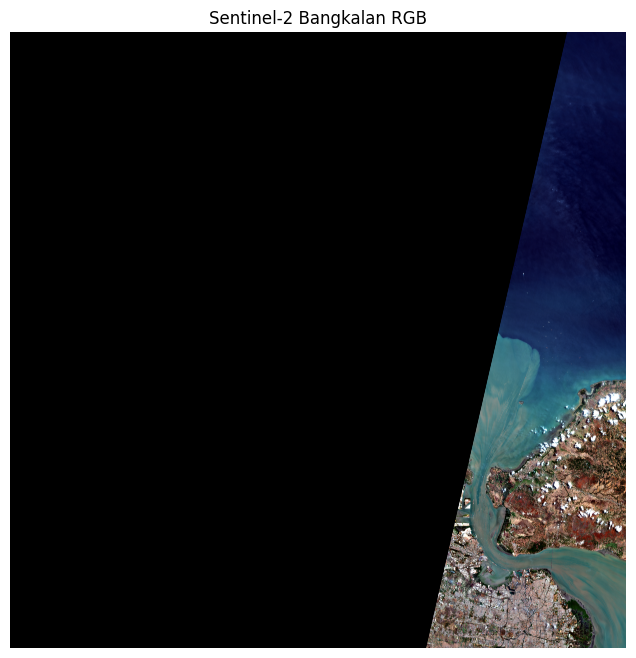

In [31]:
# B04 = Red
# B03 = Green
# B02 = Blue

rgb = np.stack(
    [
        image[2],
        image[1],
        image[0],
    ],
    axis=-1,
)

rgb_display = np.zeros_like(
    rgb,
    dtype=np.float32,
)

for i in range(3):

    band = rgb[:, :, i]

    valid = band[
        band > 0
    ]

    if len(valid):

        low, high = np.percentile(
            valid,
            [2, 98],
        )

        if high > low:

            rgb_display[
                :, :, i
            ] = np.clip(
                (band - low)
                / (high - low),
                0,
                1,
            )

plt.figure(
    figsize=(10, 8)
)

plt.imshow(
    rgb_display
)

plt.title(
    "Sentinel-2 Bangkalan RGB"
)

plt.axis("off")

plt.show()



In [32]:
bands, height, width = (
    image.shape
)

pixels = image.reshape(
    bands,
    height * width,
).T

valid = (
    np.all(
        np.isfinite(pixels),
        axis=1,
    )
    & ~np.all(
        pixels == 0,
        axis=1,
    )
)

prediction = np.zeros(
    len(pixels),
    dtype=np.uint8,
)

CHUNK_SIZE = 500_000

for start in range(
    0,
    len(pixels),
    CHUNK_SIZE,
):

    end = min(
        start + CHUNK_SIZE,
        len(pixels),
    )

    valid_chunk = valid[
        start:end
    ]

    if np.any(valid_chunk):

        indices = (
            np.arange(
                start,
                end,
            )[valid_chunk]
        )

        prediction[
            indices
        ] = rf.predict(
            pixels[indices]
        )

classification = prediction.reshape(
    height,
    width,
)

print("✓ Classification completed.")

print(
    "Sawah pixels:",
    int(
        np.sum(
            classification == 1
        )
    ),
)

print(
    "Bukan sawah pixels:",
    int(
        np.sum(
            classification == 2
        )
    ),
)



✓ Classification completed.
Sawah pixels: 3015527
Bukan sawah pixels: 22316385


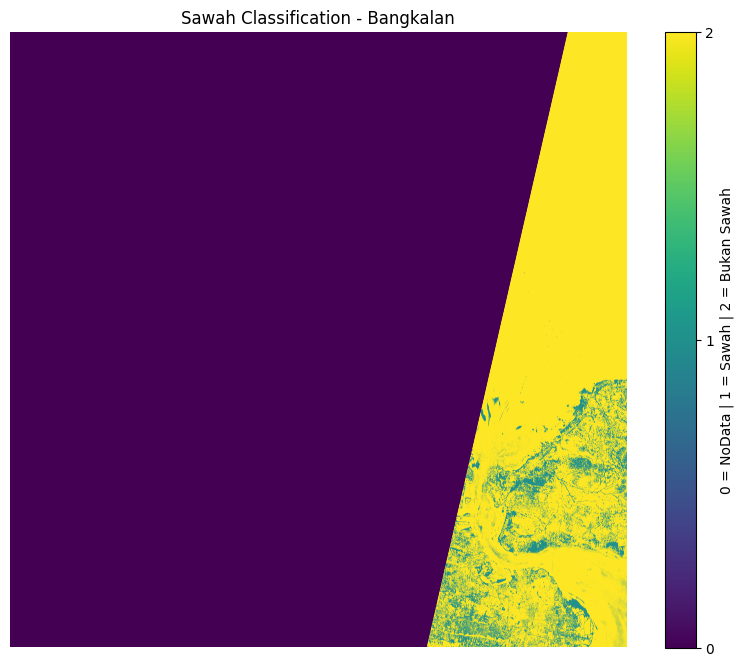

In [33]:
plt.figure(
    figsize=(10, 8)
)

plt.imshow(
    classification,
    cmap="viridis",
    vmin=0,
    vmax=2,
)

plt.title(
    "Sawah Classification - Bangkalan"
)

plt.colorbar(
    ticks=[0, 1, 2],
    label=(
        "0 = NoData | "
        "1 = Sawah | "
        "2 = Bukan Sawah"
    ),
)

plt.axis("off")

plt.show()



In [34]:
output_tif = (
    RESULTS_DIR
    / "Bangkalan_Sawah_Classification.tif"
)

output_profile = img.profile.copy()

output_profile.update(
    count=1,
    dtype="uint8",
    nodata=0,
    compress="deflate",
)

with rasterio.open(
    output_tif,
    "w",
    **output_profile,
) as dst:

    dst.write(
        classification,
        1,
    )

    dst.set_band_description(
        1,
        "Sawah Classification",
    )

print("✓ FINAL CLASSIFICATION SAVED")
print(output_tif.resolve())



✓ FINAL CLASSIFICATION SAVED
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\results\Bangkalan_Sawah_Classification.tif


In [36]:
report_path = (
    RESULTS_DIR
    / "project_information.txt"
)

with open(
    report_path,
    "w",
    encoding="utf-8",
) as f:

    f.write(
        "SAWAH CLASSIFICATION PROJECT\n"
    )
    f.write(
        "============================\n"
    )
    f.write(
        f"Student: Joni kumar Meghwar\n"
    )
    f.write(
        f"NIM: 240411100234\n"
    )
 
    f.write(
        "Imagery: Sentinel-2 L2A\n"
    )
    f.write(
        "Source: Copernicus Browser\n"
    )
    f.write(
        "Bands: B02, B03, B04, B08, B11, B12\n"
    )
    f.write(
        "Classifier: Random Forest\n"
    )
    f.write(
        f"Training polygons: {len(polygons)}\n"
    )
    f.write(
        f"Training pixels: {len(samples)}\n"
    )
    f.write(
        f"Overall Accuracy: {accuracy:.4f}\n"
    )
    f.write(
        f"Kappa: {kappa:.4f}\n"
    )

print("✓ Report saved")
print(report_path.resolve())



✓ Report saved
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\results\project_information.txt


In [37]:
print("\n" + "=" * 60)
print("PROJECT FINISHED")
print("=" * 60)

print("\nMain output:")
print(output_tif.resolve())

print("\nResults folder:")
print(RESULTS_DIR.resolve())

print("\nDONE.")



PROJECT FINISHED

Main output:
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\results\Bangkalan_Sawah_Classification.tif

Results folder:
C:\Users\Usser\Downloads\Bangkalan_Sawah_Classification_Joni_Kumar_Meghwar_Code\results

DONE.
